In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 17.3 — A Frobenius structure on Hopf algebras

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`. References below use section and equation numbers. Read the corresponding SMSA passage first. Native DisCoPy drawings run **top to bottom**: this preview reverses SMSA’s usual vertical flow while preserving left-to-right tensor order. A coupon replaces SMSA’s specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.

Equations (17.49)–(17.54): `Lambda` is the left integral $1\to H$, and `lambda` is the right cointegral $H\to1$. Empty `Ty()` is the unit. This is the literal typed translation of the two axioms, using native coupons rather than SMSA’s special integral symbols.

In [1]:
from discopy import symmetric
H = symmetric.Ty('H')
unit = symmetric.Ty()
mu = symmetric.Box('mu', H @ H, H)
Delta = symmetric.Box('Delta', H, H @ H)
eta = symmetric.Box('eta', unit, H)
epsilon = symmetric.Box('epsilon', H, unit)
Lambda = symmetric.Box('Lambda', unit, H)
cointegral = symmetric.Box('lambda', H, unit)
integral_left = (symmetric.Id(H) @ Lambda) >> mu
integral_right = epsilon >> Lambda
cointegral_left = Delta >> (cointegral @ symmetric.Id(H))
cointegral_right = cointegral >> eta
for name, left, right in [('17.50 integral', integral_left, integral_right), ('17.52 cointegral', cointegral_left, cointegral_right)]:
    print(name, '\n left:', left, '\n right:', right)
    print('Actual boundaries:', left.dom, '->', left.cod, 'and', right.dom, '->', right.cod)
    print('Both H -> H:', left.dom == left.cod == right.dom == right.cod == H)

17.50 integral 
 left: H @ Lambda >> mu 
 right: epsilon >> Lambda
Actual boundaries: H -> H and H -> H
Both H -> H: True
17.52 cointegral 
 left: Delta >> lambda @ H 
 right: lambda >> eta
Actual boundaries: H -> H and H -> H
Both H -> H: True


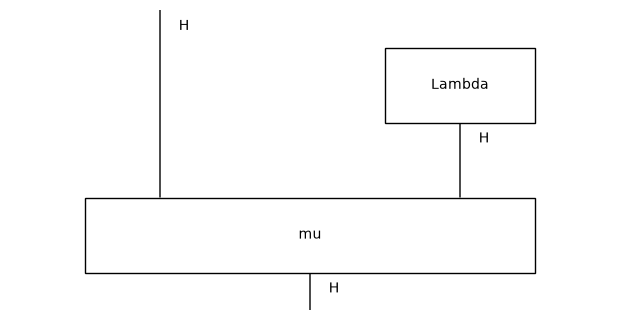

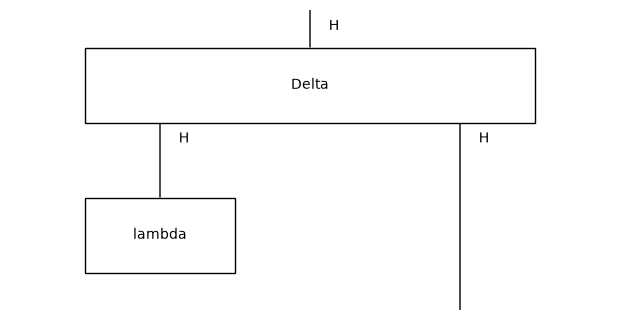

In [2]:
integral_left.draw(figsize=(6, 3))
cointegral_left.draw(figsize=(6, 3))

Example 17.3.10, (17.56), for the two-element group with ordered basis $(b_e,b_g)$: the native tensor functor uses the group-algebra maps and the supplied integral/cointegral. This evaluates the two defining equations directly.

In [3]:
from discopy import tensor
F = tensor.Functor({H: 2}, {mu: [1, 0, 0, 1, 0, 1, 1, 0], Delta: [1, 0, 0, 0, 0, 0, 0, 1], eta: [1, 0], epsilon: [1, 1], Lambda: [1, 1], cointegral: [1, 0]}, dom=symmetric.Category(), dtype=int)
for name, left, right in [('17.50 integral', integral_left, integral_right), ('17.52 cointegral', cointegral_left, cointegral_right)]:
    print(name, '\n actual left:', F(left).array, '\n expected right:', F(right).array)
    print('Equal in C[Z2]:', F(left) == F(right))

17.50 integral 
 actual left: [[1 1]
 [1 1]] 
 expected right: [[1 1]
 [1 1]]
Equal in C[Z2]: True
17.52 cointegral 
 actual left: [[1 0]
 [0 0]] 
 expected right: [[1 0]
 [0 0]]
Equal in C[Z2]: True


**Induced coproduct (17.55) and Frobenius map (17.57).** Keep the two-element example above, and now choose $G=\mathbb Z_3$ so that the antipode is visibly nontrivial. Use the ordered group basis $b_0,b_1,b_2$, product modulo 3, Hopf coproduct $b_i\mapsto b_i\otimes b_i$, integral $\Lambda=b_0+b_1+b_2$ and cointegral $\lambda(b_i)=\delta_{i,0}$. Thus $\lambda(\Lambda)=1$.

The two source diagrams (17.55) build a *new* coproduct from these maps. They give $b_i\mapsto\sum_j b_j\otimes b_{i-j}$. It is different from the Hopf copying coproduct. Relative to (17.38), this example has $\Delta_F=\Delta_{(17.38)}/3$ and $\varepsilon_F=3\varepsilon_{(17.38)}$. This normalization follows Example 17.3.10.

Native `compact` boxes allow both the Hopf maps and the bends in (17.57), with the dual printed as `H3.r`. These are algebraic duals, not adjoints. The two source constructions are transcribed with input axes before output axes.

(17.55) left, right, expected (rows=input; columns=00,01,...,22):
[[1 0 0 0 0 1 0 1 0]
 [0 1 0 1 0 0 0 0 1]
 [0 0 1 0 1 0 1 0 0]]
[[1 0 0 0 0 1 0 1 0]
 [0 1 0 1 0 0 0 0 1]
 [0 0 1 0 1 0 1 0 0]]
[[1 0 0 0 0 1 0 1 0]
 [0 1 0 1 0 0 0 0 1]
 [0 0 1 0 1 0 1 0 0]]
Both source expressions match: True


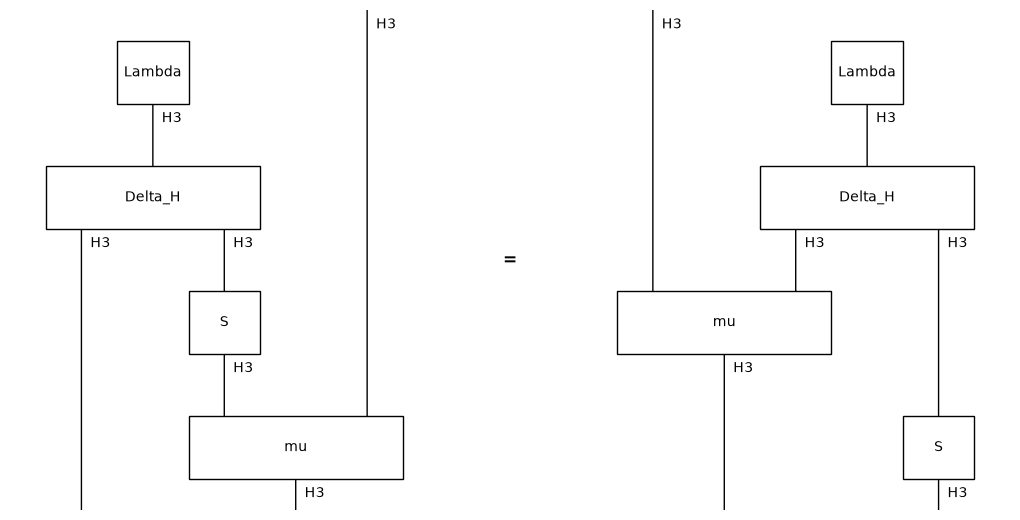

In [4]:
from discopy import compact, tensor
from discopy.drawing import Equation
import numpy as np
Q = compact.Ty('H3')
Qstar = Q.r
m3 = compact.Box('mu', Q @ Q, Q)
d3 = compact.Box('Delta_H', Q, Q @ Q)
s3 = compact.Box('S', Q, Q)
L3 = compact.Box('Lambda', compact.Ty(), Q)
l3 = compact.Box('lambda', Q, compact.Ty())
mult3 = np.array([[[int(k == (i+j)%3) for k in range(3)] for j in range(3)] for i in range(3)])
copy3 = np.array([[[int(i==j==k) for k in range(3)] for j in range(3)] for i in range(3)])
antipode3 = np.eye(3,dtype=int)[[0,2,1]]
model3 = tensor.Functor({Q:3},{m3:mult3,d3:copy3,s3:antipode3,L3:[1,1,1],l3:[1,0,0]},dom=compact.Category(),dtype=int)
frob_left = (L3 @ compact.Id(Q)) >> (d3 @ compact.Id(Q)) >> (compact.Id(Q) @ s3 @ compact.Id(Q)) >> (compact.Id(Q) @ m3)
frob_right = (compact.Id(Q) @ L3) >> (compact.Id(Q) @ d3) >> (m3 @ compact.Id(Q)) >> (compact.Id(Q) @ s3)
frob_expected = np.array([[[int((j+k)%3==i) for k in range(3)] for j in range(3)] for i in range(3)])
print('(17.55) left, right, expected (rows=input; columns=00,01,...,22):')
for value in [model3(frob_left).array,model3(frob_right).array,frob_expected]: print(value.reshape(3,9))
print('Both source expressions match:', np.array_equal(model3(frob_left).array,frob_expected) and np.array_equal(model3(frob_right).array,frob_expected))
Equation(frob_left, frob_right).draw(figsize=(10,5))


(17.57) Psi and inverse, expected identity in group/dual bases:
[[1 0 0]
 [0 1 0]
 [0 0 1]]
[[1 0 0]
 [0 1 0]
 [0 0 1]]
Expected: [[1 0 0]
 [0 1 0]
 [0 0 1]]
inverse after Psi [[1 0 0]
 [0 1 0]
 [0 0 1]] identity: True
Psi after inverse [[1 0 0]
 [0 1 0]
 [0 0 1]] identity: True
Control: replacing cointegral by Hopf counit gives composite:
[[1 1 1]
 [1 1 1]
 [1 1 1]]
Identity (expected False): False


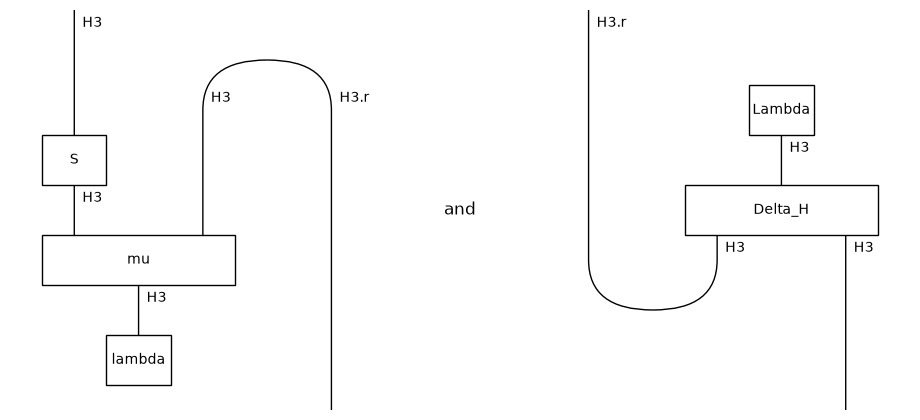

In [5]:
psi3 = (compact.Id(Q) @ compact.Cap(Q,Qstar)) >> (s3 @ compact.Id(Q @ Qstar)) >> (m3 @ compact.Id(Qstar)) >> (l3 @ compact.Id(Qstar))
psi_inverse3 = (compact.Id(Qstar) @ (L3 >> d3)) >> (compact.Cup(Qstar,Q) @ compact.Id(Q))
print('(17.57) Psi and inverse, expected identity in group/dual bases:')
print(model3(psi3).array)
print(model3(psi_inverse3).array)
print('Expected:',np.eye(3,dtype=int))
for name,composite in [('inverse after Psi',psi3 >> psi_inverse3),('Psi after inverse',psi_inverse3 >> psi3)]:
 print(name,model3(composite).array,'identity:',np.array_equal(model3(composite).array,np.eye(3,dtype=int)))
Equation(psi3,psi_inverse3,symbol='and').draw(figsize=(9,4))
wrong3 = tensor.Functor({Q:3},{m3:mult3,d3:copy3,s3:antipode3,L3:[1,1,1],l3:[1,1,1]},dom=compact.Category(),dtype=int)
print('Control: replacing cointegral by Hopf counit gives composite:')
print(wrong3(psi3 >> psi_inverse3).array)
print('Identity (expected False):', np.array_equal(wrong3(psi3 >> psi_inverse3).array,np.eye(3,dtype=int)))


The Frobenius map sends $b_i$ to the dual basis element $\beta^i$, so its matrix and the inverse matrix are both $I_3$ in these paired bases. The two inverse composites are checked explicitly. The Hopf counit $(1,1,1)$ is not the cointegral $(1,0,0)$: substituting it gives an all-ones composite, not $I_3$.

**Scope.** These are exact finite-model evaluations of (17.55) and (17.57). They do not supply the general proofs in Tasks 17.3.9 and 17.3.11 or Lemma 17.3.12.

**Hopf–Frobenius trick (17.47), and the five pictures in (17.48), pp. 379–380.**
For the same $\mathbb Z_3$ basis, both sides send
$ b_i\otimes b_j\mapsto b_{j-i}\otimes b_j$ (indices modulo 3).
The source's red multiplication nodes, blue coproduct nodes and hollow antipode nodes become coupons `mu`, `Delta_H` and `S`. Read the native drawings from top to bottom, preserving tensor order. A crossing is the native symmetric swap.

Write $\Delta(x)=\sum x_1\otimes x_2$ and $\Delta^{(2)}(x)=\sum x_1\otimes x_2\otimes x_3$. The five source pictures, in order, have outputs
$$
(S(x)y_1,y_2),\quad
(S(x_3)y_1,(x_1S(x_2))y_2),\quad
(S(x_3)y_1,x_1(S(x_2)y_2)),\quad
((S(x_2))_1y_1,x_1((S(x_2))_2y_2)),\quad
((S(x_2)y)_1,x_1(S(x_2)y)_2).
$$
Each pair denotes a tensor product, summed over the displayed coproduct indices. The next cells translate these five pictures directly and evaluate this finite example. They do not construct the inverse requested in Task 17.3.4.

(17.47) actual left, actual right, expected (input rows/output columns 00,01,...,22):
[[1 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 1 0 0]
 [0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0]
 [0 0 1 0 0 0 0 0 0]]
[[1 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 1 0 0]
 [0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0]
 [0 0 1 0 0 0 0 0 0]]
[[1 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 1 0 0]
 [0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0]
 [0 0 1 0 0 0 0 0 0]]
(17.48) picture 1 boundaries: H3 @ H3 -> H3 @ H3 expected: H3 @ H3 -> H3 @ H3
Computed basis outputs: [(0, 0), (1, 1), (2, 2), (2, 0), (0, 1), (1, 2), (1, 0), (2, 1), (0, 2)]
Expected basis outputs: [(0, 0), (1, 1), (2, 2), (2, 0), (0, 1), (1, 2), (1, 0), (2, 1), (0, 2)]
Exact full tensor equality: True
(17.48) picture 2 boundaries: H3 @ H3 -

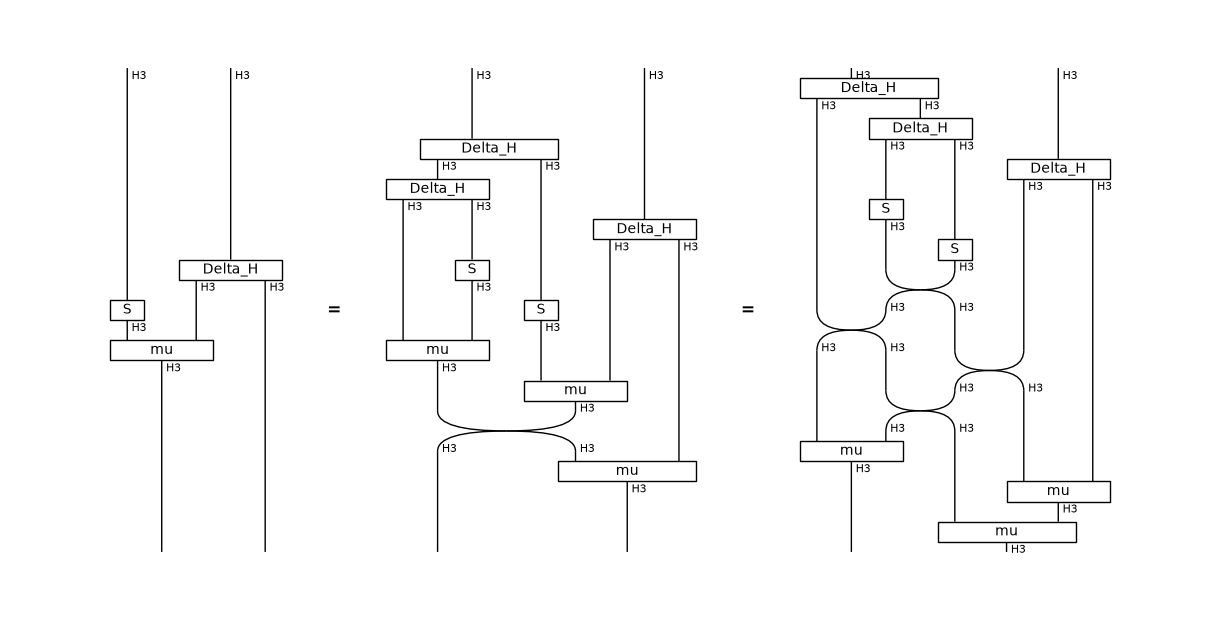

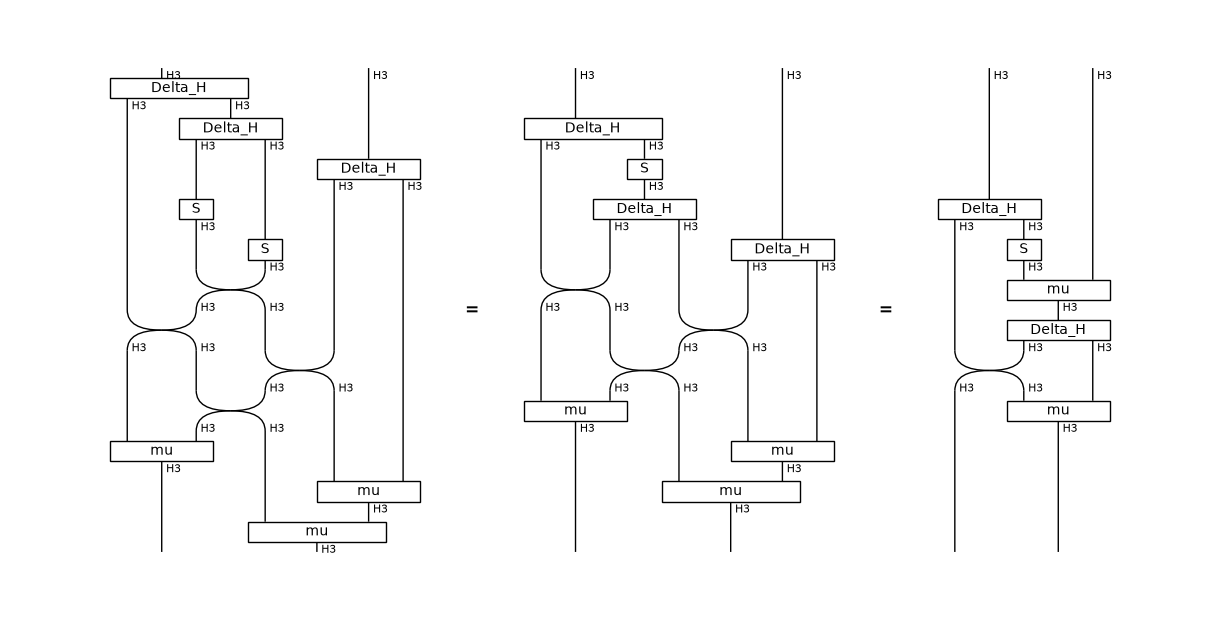

In [6]:
# SMSA 7.8, (17.47)-(17.48), pp. 379-380: five source pictures.
hopf_left = (compact.Id(Q) @ d3) >> (s3 @ compact.Id(Q @ Q)) >> (m3 @ compact.Id(Q))
hopf_stage2 = (d3 @ compact.Id(Q)) >> (d3 @ compact.Id(Q @ Q)) >> (compact.Id(Q ** 3) @ d3) >> (compact.Id(Q) @ s3 @ s3 @ compact.Id(Q @ Q)) >> (m3 @ m3 @ compact.Id(Q)) >> (compact.Swap(Q,Q) @ compact.Id(Q)) >> (compact.Id(Q) @ m3)
hopf_stage3 = (d3 @ compact.Id(Q)) >> (compact.Id(Q) @ d3 @ d3) >> (compact.Id(Q) @ s3 @ s3 @ compact.Id(Q @ Q)) >> compact.Diagram.permutation([2,3,0,1,4], Q ** 5) >> (m3 @ compact.Id(Q ** 3)) >> (compact.Id(Q @ Q) @ m3) >> (compact.Id(Q) @ m3)
hopf_stage4 = (d3 @ compact.Id(Q)) >> (compact.Id(Q) @ s3 @ compact.Id(Q)) >> (compact.Id(Q) @ d3 @ d3) >> compact.Diagram.permutation([1,3,0,2,4], Q ** 5) >> (m3 @ compact.Id(Q ** 3)) >> (compact.Id(Q @ Q) @ m3) >> (compact.Id(Q) @ m3)
hopf_right_prefix = (d3 @ compact.Id(Q)) >> (compact.Id(Q) @ s3 @ compact.Id(Q)) >> (compact.Id(Q) @ m3) >> (compact.Id(Q) @ d3) >> (compact.Swap(Q,Q) @ compact.Id(Q))
hopf_right = hopf_right_prefix >> (compact.Id(Q) @ m3)
hopf_pictures = [hopf_left,hopf_stage2,hopf_stage3,hopf_stage4,hopf_right]
hopf_expected3 = np.array([[[[int(k==(j-i)%3 and ell==j) for ell in range(3)] for k in range(3)] for j in range(3)] for i in range(3)])
print('(17.47) actual left, actual right, expected (input rows/output columns 00,01,...,22):')
for value in [model3(hopf_left).array,model3(hopf_right).array,hopf_expected3]: print(value.reshape(9,9))
for number,picture in enumerate(hopf_pictures,1):
 print('(17.48) picture',number,'boundaries:',picture.dom,'->',picture.cod,'expected:',Q@Q,'->',Q@Q)
 print('Computed basis outputs:',[tuple(int(k) for k in np.unravel_index(np.argmax(model3(picture).array[i,j]),(3,3))) for i in range(3) for j in range(3)])
 print('Expected basis outputs:',[((j-i)%3,j) for i in range(3) for j in range(3)])
 print('Exact full tensor equality:',np.array_equal(model3(picture).array,hopf_expected3))
Equation(hopf_left,hopf_stage2,hopf_stage3).draw(figsize=(12,6), margins=(0.08,0.12), fontsize=10, fontsize_types=8)
Equation(hopf_stage3,hopf_stage4,hopf_right).draw(figsize=(12,6), margins=(0.08,0.12), fontsize=10, fontsize_types=8)
no_antipode3 = tensor.Functor({Q:3},{m3:mult3,d3:copy3,s3:np.eye(3,dtype=int)},dom=compact.Category(),dtype=int)
print('Control: use identity instead of S in the left picture:')
print(no_antipode3(hopf_left).array.reshape(9,9))
print('Matches expected trick (expected False):',np.array_equal(no_antipode3(hopf_left).array,hopf_expected3))

The cyclic example distinguishes $S$ from the identity. Because its product is commutative, it cannot detect reversed inputs at a multiplication coupon. For that check, use the six permutations of three letters, in lexicographic order. Composition is $(pq)(k)=p(q(k))$ and $S(p)=p^{-1}$. This additional finite group algebra checks all five pictures on all 36 basis inputs, including the order at the final multiplication. The printed pair $(a,b)$ denotes $b_a\otimes b_b$ in this ordered basis.

In [7]:
from itertools import permutations
perms6 = list(permutations(range(3)))
product6 = np.array([[perms6.index(tuple(p[q[k]] for k in range(3))) for q in perms6] for p in perms6])
inverse6 = [perms6.index(tuple(p.index(k) for k in range(3))) for p in perms6]
mult6 = np.array([[[int(k==product6[i,j]) for k in range(6)] for j in range(6)] for i in range(6)])
copy6 = np.array([[[int(i==j==k) for k in range(6)] for j in range(6)] for i in range(6)])
model6 = tensor.Functor({Q:6},{m3:mult6,d3:copy6,s3:np.eye(6,dtype=int)[inverse6]},dom=compact.Category(),dtype=int)
hopf_expected6 = np.array([[[[int(k==product6[inverse6[i],j] and ell==j) for ell in range(6)] for k in range(6)] for j in range(6)] for i in range(6)])
print('S3 ordered permutations:',perms6)
print('Product table (row p, column q):\n',product6)
print('Inverse indices:',inverse6)
print('Expected outputs for inputs (0,0),(0,1),...,(5,5):')
print([(int(product6[inverse6[i],j]),j) for i in range(6) for j in range(6)])
for number,picture in enumerate(hopf_pictures,1):
 print('Picture',number,'computed outputs:',[tuple(int(k) for k in np.unravel_index(np.argmax(model6(picture).array[i,j]),(6,6))) for i in range(6) for j in range(6)])
 print('Exact full tensor equality:',np.array_equal(model6(picture).array,hopf_expected6))
hopf_wrong_order = hopf_right_prefix >> (compact.Id(Q) @ (compact.Swap(Q,Q) >> m3))
print('Control: reverse the final multiplication inputs (expected False):',np.array_equal(model6(hopf_wrong_order).array,hopf_expected6))
print('Input indices (1,2): actual reversed-order output:',model6(hopf_wrong_order).array[1,2])
print('Expected correct output:',hopf_expected6[1,2])

S3 ordered permutations: [(0, 1, 2), (0, 2, 1), (1, 0, 2), (1, 2, 0), (2, 0, 1), (2, 1, 0)]
Product table (row p, column q):
 [[0 1 2 3 4 5]
 [1 0 4 5 2 3]
 [2 3 0 1 5 4]
 [3 2 5 4 0 1]
 [4 5 1 0 3 2]
 [5 4 3 2 1 0]]
Inverse indices: [0, 1, 2, 4, 3, 5]
Expected outputs for inputs (0,0),(0,1),...,(5,5):
[(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (1, 0), (0, 1), (4, 2), (5, 3), (2, 4), (3, 5), (2, 0), (3, 1), (0, 2), (1, 3), (5, 4), (4, 5), (4, 0), (5, 1), (1, 2), (0, 3), (3, 4), (2, 5), (3, 0), (2, 1), (5, 2), (4, 3), (0, 4), (1, 5), (5, 0), (4, 1), (3, 2), (2, 3), (1, 4), (0, 5)]
Picture 1 computed outputs: [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (1, 0), (0, 1), (4, 2), (5, 3), (2, 4), (3, 5), (2, 0), (3, 1), (0, 2), (1, 3), (5, 4), (4, 5), (4, 0), (5, 1), (1, 2), (0, 3), (3, 4), (2, 5), (3, 0), (2, 1), (5, 2), (4, 3), (0, 4), (1, 5), (5, 0), (4, 1), (3, 2), (2, 3), (1, 4), (0, 5)]
Exact full tensor equality: True
Picture 2 computed outputs: [(0, 0), (1, 1), (2, 2), (3, 

**Scope.** The five diagrams in (17.48) agree exactly in the supplied group algebras of $\mathbb Z_3$ and $S_3$. This is finite-model evidence for the source identities, with nontrivial antipode and noncommuting multiplication controls. It is not a proof for arbitrary Hopf algebras. The source intermediate pictures have been retained rather than treating their equalities as built-in DisCoPy rewrites.